# Predicción de la esperanza de vida mediante redes neuronales

## 1. Introducción

El objetivo de esta práctica es desarrollar una red neuronal capaz de predecir la esperanza de vida de un país a partir de diferentes indicadores relacionados con la salud, la educación y la economía.

Para ello, utilizaremos el dataset **Life Expectancy (WHO)**, disponible en Kaggle, que contiene información de distintos países entre 2000 y 2015.

Primero analizaremos y prepararemos los datos. Después entrenaremos varios modelos de referencia y experimentaremos con diferentes arquitecturas y configuraciones de redes neuronales.

Finalmente, compararemos los resultados y evaluaremos la capacidad de generalización del modelo seleccionado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Life Expectancy Data.csv")

df.columns = df.columns.str.strip()

df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
df.shape


(2938, 22)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [5]:
df.isnull().sum()

Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

### Análisis de la variable objetivo

La mayoría de las observaciones presentan una esperanza de vida entre los 70 y 80 años, con una mayor concentración alrededor de los 74 años.

La distribución no es completamente simétrica, ya que presenta una cola hacia los valores más bajos, llegando aproximadamente a los 40 años.

Por lo tanto, puede que existan diferencias importantes en la esperanza de vida entre las observaciones de nuestro dataset, algo que habra que tener en cuenta durante el entrenamiento y evaluación de los modelos.


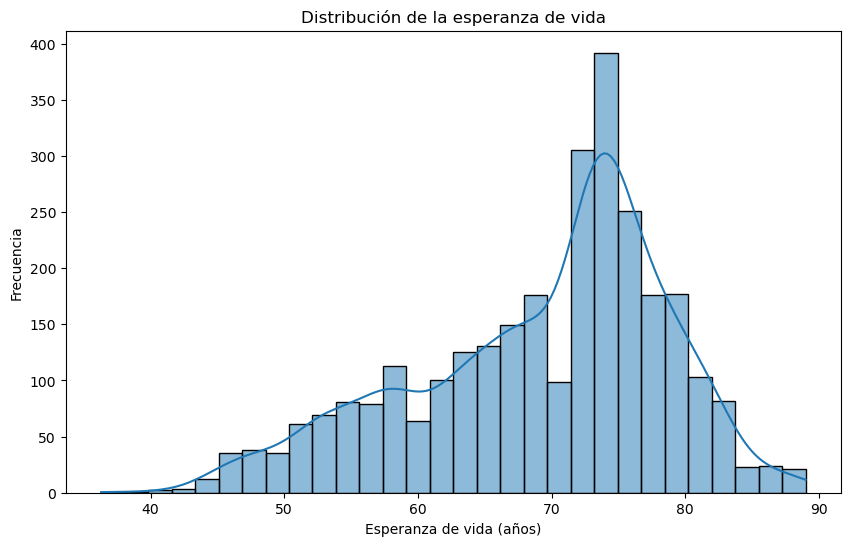

In [6]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Life expectancy",
    bins=30,
    kde=True
)

plt.title("Distribución de la esperanza de vida")

plt.xlabel("Esperanza de vida (años)")
plt.ylabel("Frecuencia")

plt.show()

### Tratamiento de valores ausentes

Hemos descubierto que algunas variables, como Population, Hepatitis B y GDP, tienen un numero considerable de valores nulos.

He decidido eliminar los 10 registros sin valor en la variable objetivo (Life expectancy), ya que no pueden utilizarse para el entrenamiento supervisado y ya que supone un numero muy pequeño.

Para el resto de variables, trataré de conservar la mayor cantidad de información posible y evitar pérdidas innecesarias de datos.


In [7]:
df.isnull().sum().sort_values(ascending=False)

Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
thinness  1-19 years                34
thinness 5-9 years                  34
BMI                                 34
Diphtheria                          19
Polio                               19
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Status                               0
Country                              0
Year                                 0
under-five deaths                    0
Measles                              0
percentage expenditure               0
HIV/AIDS                             0
dtype: int64

In [8]:
df = df.dropna(subset=["Life expectancy"]).copy()

print(df.shape)

(2928, 22)


### Análisis descriptivo de las variables

Se pueden ver grandes diferencias entre la media y la mediana de variables como GDP y Population, lo que indica distribuciones no simetricas y valores extremos.

Por ello, considero la imputación mediante la mediana para las variables numéricas, ya que es menos sensible a valores extremos que la media.


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,2928.0,2.007500e+03,4.610560e+00,2000.00000,2003.750000,2.007500e+03,2.011250e+03,2.015000e+03
Life expectancy,2928.0,6.922493e+01,9.523867e+00,36.30000,63.100000,7.210000e+01,7.570000e+01,8.900000e+01
Adult Mortality,2928.0,1.647964e+02,1.242921e+02,1.00000,74.000000,1.440000e+02,2.280000e+02,7.230000e+02
infant deaths,2928.0,3.040745e+01,1.181144e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03
Alcohol,2735.0,4.614856e+00,4.050749e+00,0.01000,0.905000,3.770000e+00,7.715000e+00,1.787000e+01
percentage expenditure,2928.0,7.403212e+02,1.990931e+03,0.00000,4.853964,6.561145e+01,4.426143e+02,1.947991e+04
Hepatitis B,2375.0,8.096084e+01,2.501834e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01
Measles,2928.0,2.427856e+03,1.148597e+04,0.00000,0.000000,1.700000e+01,3.622500e+02,2.121830e+05
BMI,2896.0,3.823539e+01,1.995959e+01,1.00000,19.300000,4.335000e+01,5.610000e+01,7.760000e+01
under-five deaths,2928.0,4.217930e+01,1.607005e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03


### Análisis de las distribuciones

Las variables GDP y Population presentan distribuciones muy asimétricas, con valores extremos que afectan considerablemente a sus medias.
Schooling presenta una distribución más equilibrada, mientras que Adult Mortality muestra cierta asimetría hacia valores elevados.

Es posible la imputación mediante la mediana y posibles transformaciones logarítmicas en las variables más asimétricas.


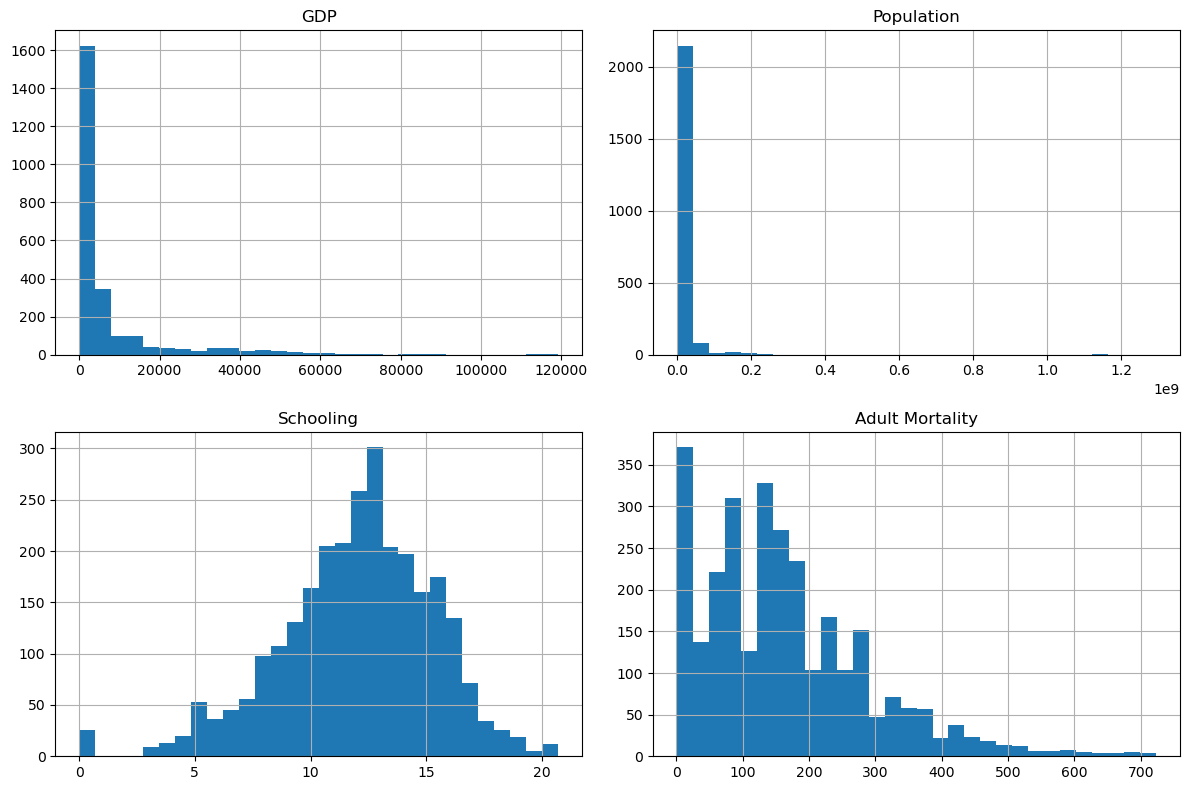

In [10]:
columnas = ["GDP", "Population", "Schooling", "Adult Mortality"]

df[columnas].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

### Análisis de correlaciones

Las variables con mayor correlación positiva con la esperanza de vida son Schooling (0.75) e Income composition of resources (0.72).

Por otro lado, Adult Mortality (-0.70) y HIV/AIDS (-0.56) presentan correlaciones negativas.

Population (-0.02) apenas tiene relación con la variable objetivo.


In [11]:
correlaciones = df.select_dtypes(include="number").corr()["Life expectancy"]

correlaciones = correlaciones.drop("Life expectancy")

correlaciones = correlaciones.sort_values(ascending=False)

print(correlaciones.round(2))

Schooling                          0.75
Income composition of resources    0.72
BMI                                0.57
Diphtheria                         0.48
Polio                              0.47
GDP                                0.46
Alcohol                            0.40
percentage expenditure             0.38
Hepatitis B                        0.26
Total expenditure                  0.22
Year                               0.17
Population                        -0.02
Measles                           -0.16
infant deaths                     -0.20
under-five deaths                 -0.22
thinness 5-9 years                -0.47
thinness  1-19 years              -0.48
HIV/AIDS                          -0.56
Adult Mortality                   -0.70
Name: Life expectancy, dtype: float64


# Analisis de correlaciones
En el primer grafico de dispersión podemos observar que para 0 años de Schooling tenemos registros de esperanza de vida de hasta
76 años aproximadamente lo que llama mi atención, por lo que decido investigar mas profundamente

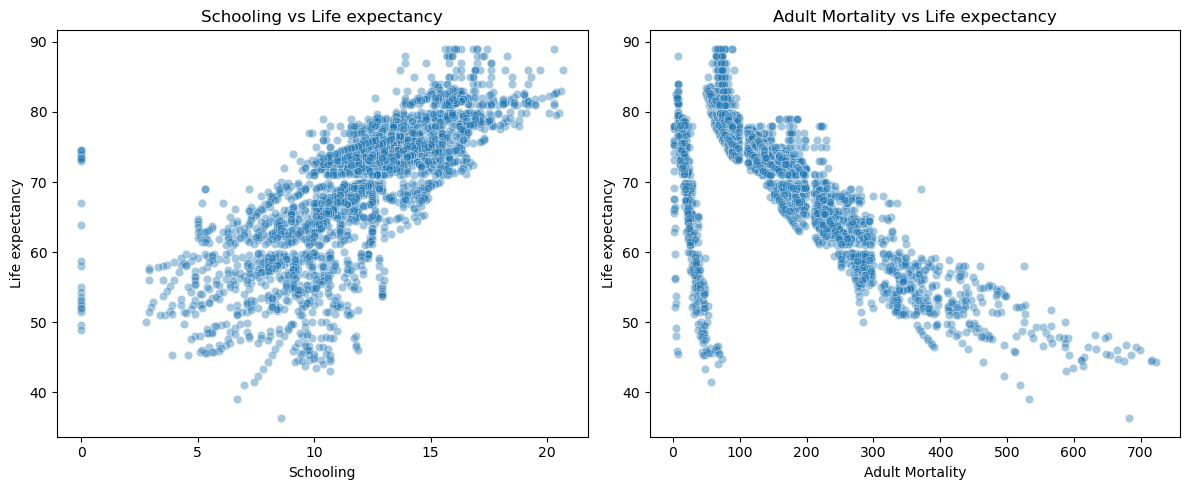

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=df,
    x="Schooling",
    y="Life expectancy",
    alpha=0.4,
    ax=axes[0]
)

axes[0].set_title("Schooling vs Life expectancy")

sns.scatterplot(
    data=df,
    x="Adult Mortality",
    y="Life expectancy",
    alpha=0.4,
    ax=axes[1]
)

axes[1].set_title("Adult Mortality vs Life expectancy")

plt.tight_layout()
plt.show()

In [13]:
df[df["Schooling"] == 0][
    ["Country", "Year", "Schooling", "Life expectancy"]
]

,Country,Year,Schooling,Life expectancy
74,Antigua and Barbuda,2005,0.0,74.6
75,Antigua and Barbuda,2004,0.0,74.4
76,Antigua and Barbuda,2003,0.0,74.2
77,Antigua and Barbuda,2002,0.0,74.0
78,Antigua and Barbuda,2001,0.0,73.8
79,Antigua and Barbuda,2000,0.0,73.6
335,Bosnia and Herzegovina,2000,0.0,74.6
849,Equatorial Guinea,2000,0.0,52.7
1714,Micronesia (Federated States of),2000,0.0,67.0
1744,Montenegro,2003,0.0,73.5


# Analisis de correlaciones
Al ordenar por año justamente en el pais Antigua and Barbuda podemos observar que hay un cambio repentino en los años de 
escolarización lo que me hace pensar que probablemente los datos estén mal introducidos y haya que tratar los "0" por NaN

In [14]:
df[df["Country"] == "Antigua and Barbuda"][
    ["Year", "Schooling"]
].sort_values("Year")

,Year,Schooling
79,2000,0.0
78,2001,0.0
77,2002,0.0
76,2003,0.0
75,2004,0.0
74,2005,0.0
73,2006,14.7
72,2007,14.5
71,2008,14.4
70,2009,14.2


In [15]:
df["Schooling"] = df["Schooling"].replace(0, np.nan)

print(df["Schooling"].isnull().sum())

186


### División de los datos

Dividimos los datos en tres conjuntos: 70% para entrenamiento, 15% para validación y 15% para test, aproximadamente.

Como tenemos información de los mismos países en diferentes años, hacemos la división por países para evitar que los datos de un mismo país aparezcan en varios conjuntos.

Para ello, utilizamos `train_test_split` en dos pasos y después seleccionamos los registros que corresponden a cada grupo de países.


In [16]:
from sklearn.model_selection import train_test_split

paises = df["Country"].unique()

paises_train, paises_temp = train_test_split(
    paises,
    test_size=0.30,
    random_state=42
)

paises_val, paises_test = train_test_split(
    paises_temp,
    test_size=0.50,
    random_state=42
)

train_df = df[df["Country"].isin(paises_train)].copy()
val_df = df[df["Country"].isin(paises_val)].copy()
test_df = df[df["Country"].isin(paises_test)].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (2048, 22)
Validation: (432, 22)
Test: (448, 22)


In [17]:

X_train = train_df.drop(columns=["Life expectancy", "Country"])
y_train = train_df["Life expectancy"]

X_val = val_df.drop(columns=["Life expectancy", "Country"])
y_val = val_df["Life expectancy"]

X_test = test_df.drop(columns=["Life expectancy", "Country"])
y_test = test_df["Life expectancy"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (2048, 20)
y_train: (2048,)


### Imputación de valores nulos

Para tratar los valores ausentes de las variables numéricas, utilizamos SimpleImputer con la mediana, ya que algunas variables presentan valores extremos que pueden afectar a la media.

El imputador se ajusta únicamente con los datos de entrenamiento y después se aplica a validación y test para evitar fugas de información.


In [18]:
from sklearn.impute import SimpleImputer

columnas_numericas = X_train.select_dtypes(include="number").columns

imputer = SimpleImputer(strategy="median")

X_train[columnas_numericas] = imputer.fit_transform(X_train[columnas_numericas])

X_val[columnas_numericas] = imputer.transform(X_val[columnas_numericas])

X_test[columnas_numericas] = imputer.transform(X_test[columnas_numericas])

### Codificación de variables categóricas

La variable Status contiene dos categorías: Developed y Developing. Para poder utilizarla en los modelos, la convertimos en una variable binaria, asignando 1 a Developed y 0 a Developing.


In [19]:

X_train["Status"] = X_train["Status"].map({"Developing": 0, "Developed": 1})

X_val["Status"] = X_val["Status"].map({"Developing": 0, "Developed": 1})

X_test["Status"] = X_test["Status"].map({"Developing": 0, "Developed": 1})

### Escalado de características

Como las variables tienen escalas muy diferentes, utilizamos StandardScaler para estandarizarlas y facilitar el entrenamiento de las redes neuronales.

El escalador se ajusta únicamente con los datos de entrenamiento y se aplica posteriormente a validación y test para evitar fugas de información. Mantenemos Status sin escalar porque ya está codificada con valores 0 y 1.


In [20]:
from sklearn.preprocessing import StandardScaler

columnas_escalar = X_train.columns.drop("Status")

scaler = StandardScaler()

X_train[columnas_escalar] = scaler.fit_transform(X_train[columnas_escalar])

X_val[columnas_escalar] = scaler.transform(X_val[columnas_escalar])

X_test[columnas_escalar] = scaler.transform(X_test[columnas_escalar])

X_train.head()

,Year,Status,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,1.626978,0,0.772742,0.233518,-1.201422,-0.357516,-0.768744,-0.071767,-1.001074,0.220102,-3.225601,0.939577,-0.706277,-0.336222,-0.484237,0.370736,2.837467,2.793758,-0.787982,-0.684436
1,1.410048,0,0.836127,0.248318,-1.201422,-0.356327,-0.899475,-0.142112,-1.025983,0.236388,-1.022913,0.948059,-0.831787,-0.336222,-0.482066,-0.168086,2.905654,2.838368,-0.802907,-0.717000
2,1.193118,0,0.812358,0.263118,-1.201422,-0.356488,-0.812321,-0.148700,-1.050891,0.252674,-0.853475,0.926853,-0.748114,-0.336222,-0.480611,0.338402,2.951112,2.882978,-0.832756,-0.749563
3,0.976187,0,0.844050,0.285317,-1.201422,-0.353857,-0.681590,0.101757,-1.075800,0.274389,-0.641679,1.092255,-0.622604,-0.336222,-0.477693,-0.113745,2.996570,2.949893,-0.867581,-0.782127
4,0.759257,0,0.867819,0.300117,-1.201422,-0.391527,-0.638014,0.125772,-1.095727,0.296104,-0.599319,0.816586,-0.580768,-0.336222,-0.523996,-0.125330,3.064757,2.994503,-0.912356,-0.879817


### 3.1. Regresión lineal

Como primer modelo baseline utilizamos una regresión lineal, que nos servirá como referencia para comparar los resultados de los siguientes modelos.

Entrenamos el modelo con `X_train` e `y_train` y después realizamos predicciones tanto en entrenamiento como en validación, para comprobar su rendimiento con datos conocidos y no vistos.

Para evaluarlo utilizaremos las métricas MAE, RMSE y R².


In [21]:
from sklearn.linear_model import LinearRegression

modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train, y_train)

pred_train = modelo_lineal.predict(X_train)
pred_val = modelo_lineal.predict(X_val)

### Resultados de la regresión lineal

El modelo obtiene un MAE de 2.97 años en entrenamiento y 3.29 en validación, con un R² de 0.83 y 0.81 respectivamente.

Los resultados son bastante similares entre ambos conjuntos, por lo que no se aprecia un sobreajuste importante.

Estos resultados nos servirán como referencia para comprobar si los siguientes modelos consiguen mejorar las predicciones.


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("RESULTADOS TRAIN")

print("MAE:", mean_absolute_error(y_train, pred_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train, pred_train)))
print("R²:", r2_score(y_train, pred_train))

print("\nRESULTADOS VALIDATION")

print("MAE:", mean_absolute_error(y_val, pred_val))
print("RMSE:", np.sqrt(mean_squared_error(y_val, pred_val)))
print("R²:", r2_score(y_val, pred_val))

RESULTADOS TRAIN
MAE: 2.9723705382392622
RMSE: 3.9751776012044857
R²: 0.8303798647006847

RESULTADOS VALIDATION
MAE: 3.2944869210024867
RMSE: 4.298400883620238
R²: 0.8101676104986023


### 3.2. Random Forest

Como segundo baseline utilizamos Random Forest, un modelo basado en varios árboles de decisión que combina sus predicciones.

Utilizamos 100 árboles y dejamos el resto de parámetros por defecto, ya que buscamos un modelo inicial sencillo con el que comparar posteriormente nuestras redes neuronales.


In [23]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_rf.fit(X_train, y_train)

pred_train_rf = modelo_rf.predict(X_train)
pred_val_rf = modelo_rf.predict(X_val)

In [24]:
print("RESULTADOS TRAIN")

print("MAE:", mean_absolute_error(y_train, pred_train_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_train, pred_train_rf)))
print("R²:", r2_score(y_train, pred_train_rf))

print("\nRESULTADOS VALIDATION")

print("MAE:", mean_absolute_error(y_val, pred_val_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_val, pred_val_rf)))
print("R²:", r2_score(y_val, pred_val_rf))

RESULTADOS TRAIN
MAE: 0.3941738281249998
RMSE: 0.6757030503887688
R²: 0.9950990971794389

RESULTADOS VALIDATION
MAE: 1.9083171296296302
RMSE: 2.7715972234402084
R²: 0.9210746137540735


### Resultados de Random Forest

Random Forest consigue mejores resultados que la regresión lineal, reduciendo el MAE de validación de 3.29 a 1.91 años y aumentando el R² hasta 0.92.

Sin embargo, existe una diferencia notable entre el error de entrenamiento (0.39) y el de validación (1.91), lo que indica cierto sobreajuste. Aun así, el modelo presenta un buen rendimiento con los datos de validación.


### 3.3. Red neuronal MLP

Como tercer baseline construimos una red neuronal MLP sencilla, formada por una capa oculta de 32 neuronas con activación ReLU y una neurona de salida para predecir la esperanza de vida.

Utilizamos el optimizador Adam y el error cuadrático medio (MSE) como función de pérdida.


In [25]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

modelo_mlp = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

modelo_mlp.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

modelo_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 705 (2.75 KB)

 Trainable params: 705 (2.75 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
modelo_mlp.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=100,
    batch_size=32
)

Epoch 1/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 4729.7314 - mae: 68.0891 - val_loss: 4504.9287 - val_mae: 66.3994
Epoch 2/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4458.0371 - mae: 66.0677 - val_loss: 4156.6436 - val_mae: 63.7433
Epoch 3/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4047.4202 - mae: 62.8655 - val_loss: 3653.6001 - val_mae: 59.6677
Epoch 4/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3504.5464 - mae: 58.2956 - val_loss: 3035.6057 - val_mae: 54.1593
Epoch 5/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2888.2744 - mae: 52.4972 - val_loss: 2386.6802 - val_mae: 47.5489
Epoch 6/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2280.3691 - mae: 45.9028 - val_loss: 1793.1943 - val_mae: 40.3697
Epoch 7/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1747.7153 - mae: 39.1214 - val_loss: 1310.3126 - val_mae: 33.2163
Epoch 8/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1323.2719 - mae: 32.9516 - val_loss: 953.1659 - val_mae: 27.0112
E

In [27]:
pred_train_mlp = modelo_mlp.predict(X_train.astype("float32"), verbose=0).ravel()
pred_val_mlp = modelo_mlp.predict(X_val.astype("float32"), verbose=0).ravel()

print("RESULTADOS MLP - TRAIN")

print("MAE:", mean_absolute_error(y_train, pred_train_mlp))
print("RMSE:", np.sqrt(mean_squared_error(y_train, pred_train_mlp)))
print("R²:", r2_score(y_train, pred_train_mlp))

print("\nRESULTADOS MLP - VALIDATION")

print("MAE:", mean_absolute_error(y_val, pred_val_mlp))
print("RMSE:", np.sqrt(mean_squared_error(y_val, pred_val_mlp)))
print("R²:", r2_score(y_val, pred_val_mlp))

RESULTADOS MLP - TRAIN
MAE: 2.6860622949898243
RMSE: 3.601917842238795
R²: 0.8607382215135215

RESULTADOS MLP - VALIDATION
MAE: 3.256153138478597
RMSE: 4.399460340557548
R²: 0.8011364010368143


### Resultados de la MLP baseline

Esta primera red neuronal obtiene un MAE de 2.69 años en entrenamiento y 3.26 en validación, con un R² de 0.80.

Su rendimiento es parecido al de la regresión lineal, aunque todavía está lejos de Random Forest, que consigue un MAE de 1.91 años.


In [28]:
def evaluar_modelo(y_real, predicciones):
    return {
        "MAE": mean_absolute_error(y_real, predicciones),
        "RMSE": np.sqrt(mean_squared_error(y_real, predicciones)),
        "R²": r2_score(y_real, predicciones)
    }

resultados_baselines = pd.DataFrame({
    "Regresión lineal Train": evaluar_modelo(y_train, pred_train),
    "Regresión lineal Val": evaluar_modelo(y_val, pred_val),

    "Random Forest Train": evaluar_modelo(y_train, pred_train_rf),
    "Random Forest Val": evaluar_modelo(y_val, pred_val_rf),

    "MLP Train": evaluar_modelo(y_train, pred_train_mlp),
    "MLP Val": evaluar_modelo(y_val, pred_val_mlp)
}).T

display(resultados_baselines.round(3))

,MAE,RMSE,R²
Regresión lineal Train,2.972,3.975,0.830
Regresión lineal Val,3.294,4.298,0.810
Random Forest Train,0.394,0.676,0.995
Random Forest Val,1.908,2.772,0.921
MLP Train,2.686,3.602,0.861
MLP Val,3.256,4.399,0.801


## 4. Exploración de arquitecturas y entrenamiento

### 4.1. Experimento 1: número de épocas

En la MLP baseline observamos que los errores seguían disminuyendo al finalizar las 100 épocas.

Para comprobar si el modelo puede mejorar con más entrenamiento, mantenemos la misma arquitectura de 32 neuronas y aumentamos las épocas de 100 a 300.

Con este experimento buscamos analizar si el error de validación continúa disminuyendo o aparecen señales de sobreajuste.


In [29]:
tf.keras.utils.set_random_seed(42)

modelo_mlp_300 = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

modelo_mlp_300.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

historial_300 = modelo_mlp_300.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

print("MAE Train:", historial_300.history["mae"][-1])
print("MAE Validation:", historial_300.history["val_mae"][-1])

MAE Train: 1.696723222732544
MAE Validation: 2.681203603744507


**Conclusión del experimento**

Al aumentar el entrenamiento de 100 a 300 épocas, conseguimos reducir el MAE de validación de 3.26 a 2.68 años.

En la gráfica observamos que ambos errores disminuyen, aunque a partir de unas 150 épocas el error de validación comienza a estabilizarse, mientras que el de entrenamiento continúa bajando.

No se aprecia un sobreajuste claro, pero sí una diferencia entre ambos errores. Aumentar las épocas mejora el rendimiento, aunque las mejoras son cada vez menores.


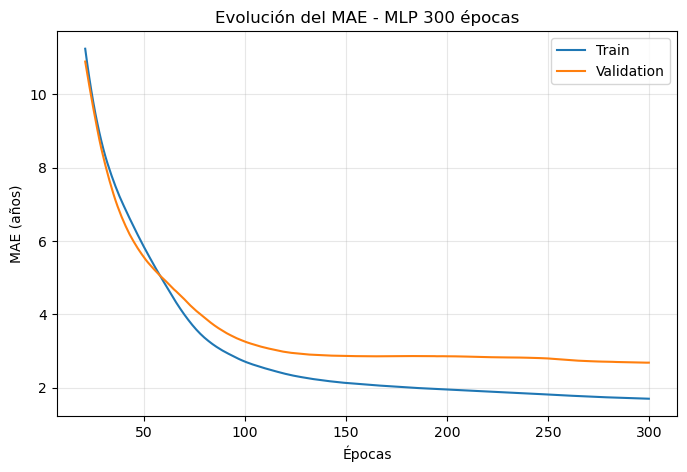

In [30]:
plt.figure(figsize=(8, 5))

epocas = range(21, 301)

plt.plot(epocas, historial_300.history["mae"][20:], label="Train")
plt.plot(epocas, historial_300.history["val_mae"][20:], label="Validation")

plt.xlabel("Épocas")
plt.ylabel("MAE (años)")
plt.title("Evolución del MAE - MLP 300 épocas")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Conclusión**

Al aumentar el entrenamiento de 100 a 300 épocas, el MAE de validación disminuye de 3.26 a 2.68 años y el R² aumenta de 0.80 a 0.86.

Observamos que la red mejora con más entrenamiento, aunque la diferencia entre los errores de entrenamiento y validación aumenta.

Por tanto, las 100 épocas iniciales no eran suficientes para obtener el mejor rendimiento de esta arquitectura. A continuación, comprobaré si modificar el número de neuronas permite mejorar los resultados.


In [31]:
pred_train_300 = modelo_mlp_300.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_300 = modelo_mlp_300.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("RESULTADOS MLP 300 ÉPOCAS - TRAIN")
print(evaluar_modelo(y_train, pred_train_300))

print("\nRESULTADOS MLP 300 ÉPOCAS - VALIDATION")
print(evaluar_modelo(y_val, pred_val_300))

RESULTADOS MLP 300 ÉPOCAS - TRAIN
{'MAE': 1.6707079984247684, 'RMSE': np.float64(2.3184674373553045), 'R²': 0.9423012594697964}

RESULTADOS MLP 300 ÉPOCAS - VALIDATION
{'MAE': 2.681203796245433, 'RMSE': np.float64(3.6284794434819663), 'R²': 0.8647286529669902}


### 4.2. Experimento 2: número de neuronas

En este experimento aumentamos las neuronas de la capa oculta de 32 a 64, manteniendo las 300 épocas y el resto de la configuración.

El objetivo es comprobar si una red con mayor capacidad de aprendizaje mejora las predicciones o provoca un mayor sobreajuste.


In [32]:

tf.keras.utils.set_random_seed(42)

modelo_mlp_64 = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1)
])

modelo_mlp_64.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

historial_64 = modelo_mlp_64.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

In [33]:

pred_train_64 = modelo_mlp_64.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_64 = modelo_mlp_64.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("RESULTADOS MLP 64 NEURONAS - TRAIN")
print(evaluar_modelo(y_train, pred_train_64))

print("\nRESULTADOS MLP 64 NEURONAS - VALIDATION")
print(evaluar_modelo(y_val, pred_val_64))

RESULTADOS MLP 64 NEURONAS - TRAIN
{'MAE': 1.2319247748702766, 'RMSE': np.float64(1.7879606861904287), 'R²': 0.9656852955620001}

RESULTADOS MLP 64 NEURONAS - VALIDATION
{'MAE': 2.4512144706867356, 'RMSE': np.float64(3.3919926280202355), 'R²': 0.8817867165876002}


**Conclusión**

Al aumentar las neuronas de 32 a 64, el MAE de validación disminuye de 2.68 a 2.45 años y el R² aumenta de 0.865 a 0.882.

Esto indica que aumentar la capacidad de la red ha mejorado las predicciones. Sin embargo, también observamos una mayor diferencia entre los errores de entrenamiento y validación, por lo que conviene analizar las curvas de aprendizaje para detectar un posible sobreajuste.

### 4.3. Experimento 3: profundidad de la red

Añadimos una segunda capa oculta de 32 neuronas, manteniendo las 64 neuronas de la primera capa y el resto de la configuración.

El objetivo es comprobar si aumentar la profundidad de la red mejora el rendimiento frente a una única capa oculta.

In [34]:
tf.keras.utils.set_random_seed(42)

modelo_mlp_2capas = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

modelo_mlp_2capas.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

historial_2capas = modelo_mlp_2capas.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

In [35]:
pred_train_2capas = modelo_mlp_2capas.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_2capas = modelo_mlp_2capas.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_2capas))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_2capas))

TRAIN
{'MAE': 0.9458902802318336, 'RMSE': np.float64(1.3745883583474507), 'R²': 0.9797180524656024}

VALIDATION
{'MAE': 2.7008881886800133, 'RMSE': np.float64(4.000706540214531), 'R²': 0.8355515164159582}


**Conclusión**

Al añadir una segunda capa oculta, el MAE de entrenamiento disminuye de 1.23 a 0.95 años, pero el de validación aumenta de 2.45 a 2.70.

Esto puede dar a entender cierto sobreajuste, ya que la red se ajusta mejor a los datos de entrenamiento, pero pierde capacidad de generalizar.

### 4.4. Experimento 4: función de activación

Comparamos la función de activación ReLU con tanh, utilizando una capa oculta de 64 neuronas y manteniendo el resto de parámetros.

In [36]:
tf.keras.utils.set_random_seed(42)

modelo_tanh = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(1)
])

modelo_tanh.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

historial_tanh = modelo_tanh.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_tanh = modelo_tanh.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_tanh = modelo_tanh.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_tanh))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_tanh))

TRAIN
{'MAE': 1.4650341387838126, 'RMSE': np.float64(2.0942176752809747), 'R²': 0.9529230873682915}

VALIDATION
{'MAE': 2.101097145786992, 'RMSE': np.float64(2.9242776733503932), 'R²': 0.9121394944901415}


**Conclusión**

Al sustituir ReLU por tanh, el MAE de validación disminuye de 2.45 a 2.10 años y el R² aumenta de 0.882 a 0.912.

Aunque tanh obtiene un error mayor en entrenamiento, consigue mejores resultados en validación, lo que indica una mejor generalización.

De momento, la arquitectura de una capa oculta de 64 neuronas con activación tanh es la mejor.

### 4.5. Experimento 5: función de pérdida

Comparamos las funciones de pérdida MSE y MAE utilizando nuestra mejor arquitectura hasta ahora: una capa oculta de 64 neuronas con activación tanh.

In [37]:
tf.keras.utils.set_random_seed(42)

modelo_loss_mae = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(1)
])

modelo_loss_mae.compile(
    optimizer="adam",
    loss="mae",
    metrics=["mae"]
)

historial_loss_mae = modelo_loss_mae.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_loss_mae = modelo_loss_mae.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_loss_mae = modelo_loss_mae.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_loss_mae))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_loss_mae))

TRAIN
{'MAE': 1.3688385777175427, 'RMSE': np.float64(2.2862830248155244), 'R²': 0.943892061067696}

VALIDATION
{'MAE': 1.945240711282801, 'RMSE': np.float64(2.882685892832114), 'R²': 0.914620987719569}


**Conclusión TOP 1**

Al cambiar la función de pérdida de MSE a MAE, el error de validación disminuye de 2.10 a 1.95 años y el R² mejora ligeramente.

Por tanto, MAE ha dado mejores resultados en esta configuración y lo mantendremos para los siguientes experimentos. Además, ya se obtiene un rendimiento muy cercano al de Random Forest.

## 5. Regularización

### 5.1. Regularización L2

Aplico regularización L2 a la mejor arquitectura neuronal para comprobar si se consigue reducir el sobreajuste y mejorar la generalización.

Mantendré la configuración anterior, añadiendo únicamente una penalización L2 de 0.001 a los pesos de la capa oculta.

In [38]:
tf.keras.utils.set_random_seed(42)

modelo_l2 = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(
        64,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(0.001)
    ),
    tf.keras.layers.Dense(1)
])

modelo_l2.compile(
    optimizer="adam",
    loss="mae",
    metrics=["mae"]
)

historial_l2 = modelo_l2.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_l2 = modelo_l2.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_l2 = modelo_l2.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_l2))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_l2))

TRAIN
{'MAE': 1.4782419435679914, 'RMSE': np.float64(2.385304584290827), 'R²': 0.9389266113139679}

VALIDATION
{'MAE': 2.053666293179547, 'RMSE': np.float64(2.8979443797363773), 'R²': 0.9137147478956669}


**Conclusión**

Al aplicar regularización L2 con un valor de 0.001, el MAE de validación aumenta de 1.95 a 2.05 años.

La regularización no consigue mejorar el rendimiento ni reducir de forma apreciable la diferencia entre entrenamiento y validación.

Por tanto, en esta configuración no considero beneficioso utilizar L2.

### 5.2. Regularización Dropout

Probamos Dropout con una tasa de 0.2 sobre nuestra arquitectura de 64 neuronas y activación tanh.

In [39]:
tf.keras.utils.set_random_seed(42)

modelo_dropout = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1)
])

modelo_dropout.compile(
    optimizer="adam",
    loss="mae",
    metrics=["mae"]
)

historial_dropout = modelo_dropout.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_dropout = modelo_dropout.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_dropout = modelo_dropout.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_dropout))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_dropout))

TRAIN
{'MAE': 1.8114507492631675, 'RMSE': np.float64(2.6176166124077898), 'R²': 0.926451061620334}

VALIDATION
{'MAE': 2.513903828020449, 'RMSE': np.float64(3.8099767302238776), 'R²': 0.8508576001206903}


**Conclusión**

Al aplicar Dropout de 0.2, el MAE de validación aumenta de 1.95 a 2.51 años, empeorando el rendimiento respecto al modelo sin regularización.

### 5.3. Batch Normalization

Pruebo Batch Normalization en nuestra arquitectura de 64 neuronas con activación tanh.

In [40]:
tf.keras.utils.set_random_seed(42)

modelo_bn = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("tanh"),
    tf.keras.layers.Dense(1)
])

modelo_bn.compile(
    optimizer="adam",
    loss="mae",
    metrics=["mae"]
)

historial_bn = modelo_bn.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_bn = modelo_bn.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_bn = modelo_bn.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_bn))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_bn))

TRAIN
{'MAE': 1.7026323184370993, 'RMSE': np.float64(2.4425890856657806), 'R²': 0.9359579601660819}

VALIDATION
{'MAE': 2.3379648950364857, 'RMSE': np.float64(3.2233142566683424), 'R²': 0.893251500558372}


**Conclusión**

Al aplicar Batch Normalization, el MAE de validación aumenta de 1.95 a 2.34 años, por lo que tampoco se consigue mejorar el rendimiento.

Tras comparar L2, Dropout y Batch Normalization, ninguna de las configuraciones probadas supera al modelo sin regularización. Por tanto, continuaré utilizando la arquitectura original de 64 neuronas con activación tanh.

## 6. Comparación de optimizadores

Vamos a comparar Adam, RMSprop y SGD para comprobar cómo influye el algoritmo de optimización en el aprendizaje de la red neuronal.

Se utilizará la arquitectura de 64 neuronas con activación tanh, sin regularización.

In [41]:
tf.keras.utils.set_random_seed(42)

modelo_rmsprop = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(1)
])

modelo_rmsprop.compile(
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001),
    loss="mae",
    metrics=["mae"]
)

historial_rmsprop = modelo_rmsprop.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_rmsprop = modelo_rmsprop.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_rmsprop = modelo_rmsprop.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_rmsprop))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_rmsprop))

TRAIN
{'MAE': 1.3716257948428392, 'RMSE': np.float64(2.2840233779715193), 'R²': 0.9440029147741162}

VALIDATION
{'MAE': 2.1708781207049332, 'RMSE': np.float64(3.1051464859771145), 'R²': 0.900934903570021}


**Comparación Adam vs. RMSprop**

Ambos optimizadores obtienen resultados similares en entrenamiento, pero Adam consigue un menor MAE en validación (1.95 frente a 2.17 años).

Por tanto, Adam generaliza mejor en este experimento. A continuación, compararemos ambos con SGD.

### 6.2. Optimizador SGD

Probamos SGD con un learning rate de 0.001, manteniendo la misma arquitectura y condiciones de entrenamiento utilizadas con Adam y RMSprop.

In [42]:
tf.keras.utils.set_random_seed(42)

modelo_sgd = tf.keras.Sequential([
    tf.keras.Input(shape=(20,)),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(1)
])

modelo_sgd.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
    loss="mae",
    metrics=["mae"]
)

historial_sgd = modelo_sgd.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_sgd = modelo_sgd.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_sgd = modelo_sgd.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_sgd))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_sgd))

TRAIN
{'MAE': 1.7736417539417744, 'RMSE': np.float64(2.6815702708774696), 'R²': 0.9228132604264541}

VALIDATION
{'MAE': 2.2592955094796636, 'RMSE': np.float64(3.14380637979765), 'R²': 0.898452774353593}


**Conclusión**

Tras comparar Adam, RMSprop y SGD con un learning rate de 0.001, Adam obtiene el mejor resultado en validación, con un MAE de 1.95 años, frente a 2.17 de RMSprop y 2.26 de SGD.

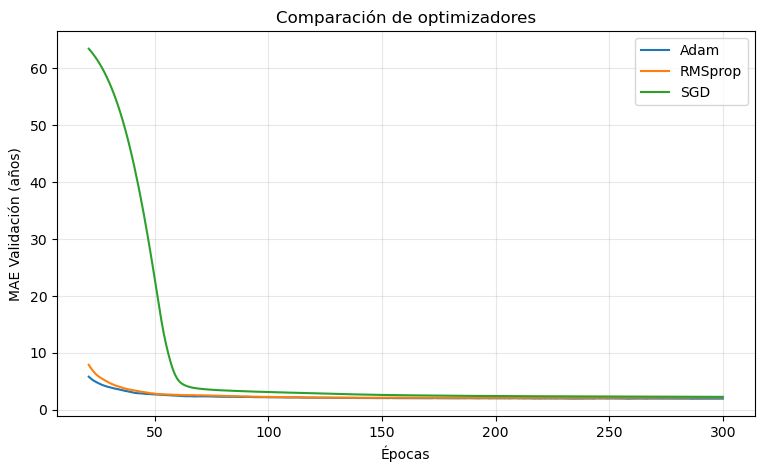

In [43]:
plt.figure(figsize=(9, 5))

epocas = range(21, 301)

plt.plot(epocas, historial_loss_mae.history["val_mae"][20:], label="Adam")
plt.plot(epocas, historial_rmsprop.history["val_mae"][20:], label="RMSprop")
plt.plot(epocas, historial_sgd.history["val_mae"][20:], label="SGD")

plt.xlabel("Épocas")
plt.ylabel("MAE Validación (años)")
plt.title("Comparación de optimizadores")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Análisis de convergencia**

En la gráfica observamos que Adam y RMSprop reducen rápidamente el error, mientras que SGD necesita más épocas para alcanzar resultados similares.

Adam consigue el menor MAE de validación (1.95 años), seguido de RMSprop (2.17) y SGD (2.26). Por tanto, selecciono Adam para continuar.

## 7. Búsqueda de hiperparámetros

Utilizo Random Search con KerasTuner para buscar una configuración adecuada de la MLP.

Exploraremos diferentes números de neuronas y valores de learning rate, manteniendo la activación tanh y el optimizador Adam.

Limito inicialmente la búsqueda a cuatro combinaciones.

In [44]:
import keras_tuner as kt

def crear_modelo(hp):

    modelo = tf.keras.Sequential([
        tf.keras.Input(shape=(20,)),

        tf.keras.layers.Dense(
            units=hp.Choice("neuronas", [32, 64, 128]),
            activation="tanh"
        ),

        tf.keras.layers.Dense(1)
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice("learning_rate", [0.0005, 0.001, 0.002])
        ),
        loss="mae",
        metrics=["mae"]
    )

    return modelo

In [45]:
tf.keras.utils.set_random_seed(42)

tuner = kt.RandomSearch(
    crear_modelo,
    objective="val_mae",
    max_trials=4,
    seed=42,
    directory="tuner_rna",
    project_name="busqueda_mlp",
    overwrite=True
)

tuner.search(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=150,
    batch_size=32,
    verbose=0
)

mejores_parametros = tuner.get_best_hyperparameters(1)[0]

print("Mejor número de neuronas:", mejores_parametros.get("neuronas"))
print("Mejor learning rate:", mejores_parametros.get("learning_rate"))

print("Mejor MAE de validación:",
      tuner.oracle.get_best_trials(1)[0].score)


Mejor número de neuronas: 128
Mejor learning rate: 0.001
Mejor MAE de validación: 2.0901269912719727


### 7.1. Evaluación de los mejores hiperparámetros

KerasTuner ha seleccionado una arquitectura de 128 neuronas y un learning rate de 0.001, obteniendo un MAE de validación de 2.09 años durante la búsqueda de 150 épocas.

Para comparar esta configuración con los modelos anteriores, entrenaremos una nueva red durante 300 épocas y evaluaremos sus resultados en entrenamiento y validación.

In [46]:
tf.keras.utils.set_random_seed(42)

modelo_optimizado = crear_modelo(mejores_parametros)

historial_optimizado = modelo_optimizado.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_data=(
        X_val.astype("float32"),
        y_val.astype("float32")
    ),
    epochs=300,
    batch_size=32,
    verbose=0
)

pred_train_opt = modelo_optimizado.predict(
    X_train.astype("float32"), verbose=0
).ravel()

pred_val_opt = modelo_optimizado.predict(
    X_val.astype("float32"), verbose=0
).ravel()

print("TRAIN")
print(evaluar_modelo(y_train, pred_train_opt))

print("\nVALIDATION")
print(evaluar_modelo(y_val, pred_val_opt))

TRAIN
{'MAE': 1.2451926365494728, 'RMSE': np.float64(2.157494646792761), 'R²': 0.9500352423048969}

VALIDATION
{'MAE': 2.244714445537991, 'RMSE': np.float64(3.162503529710854), 'R²': 0.8972413195946041}


**Conclusión**

KerasTuner seleccionó una arquitectura de 128 neuronas con un learning rate de 0.001.

Al entrenarla durante 300 épocas, obtenemos un MAE de validación de 2.24 años, superior al de nuestra red anterior de 64 neuronas (1.95).

Aunque la nueva arquitectura obtiene mejores resultados en entrenamiento, no consigue mejorar la generalización. Por tanto, mantenemos la MLP de 64 neuronas con activación tanh como nuestra mejor propuesta hasta ahora.

In [47]:
modelos = {
    "Regresión lineal": (pred_train, pred_val),
    "Random Forest": (pred_train_rf, pred_val_rf),
    "MLP 32 - 100 épocas": (pred_train_mlp, pred_val_mlp),
    "MLP 32 - 300 épocas": (pred_train_300, pred_val_300),
    "MLP 64 - ReLU": (pred_train_64, pred_val_64),
    "MLP 64-32 - ReLU": (pred_train_2capas, pred_val_2capas),
    "MLP 64 - tanh + MSE": (pred_train_tanh, pred_val_tanh),
    "MLP 64 - tanh + MAE": (pred_train_loss_mae, pred_val_loss_mae),
    "MLP + L2": (pred_train_l2, pred_val_l2),
    "MLP + Dropout": (pred_train_dropout, pred_val_dropout),
    "MLP + BatchNorm": (pred_train_bn, pred_val_bn),
    "MLP + RMSprop": (pred_train_rmsprop, pred_val_rmsprop),
    "MLP + SGD": (pred_train_sgd, pred_val_sgd),
    "MLP 128 - KerasTuner": (pred_train_opt, pred_val_opt)
}

resultados = []

for nombre, (pred_tr, pred_v) in modelos.items():

    train = evaluar_modelo(y_train, pred_tr)
    val = evaluar_modelo(y_val, pred_v)

    resultados.append({
        "Modelo": nombre,
        "MAE Train": train["MAE"],
        "MAE Val": val["MAE"],
        "RMSE Train": train["RMSE"],
        "RMSE Val": val["RMSE"],
        "R² Train": train["R²"],
        "R² Val": val["R²"]
    })

tabla_resultados = pd.DataFrame(resultados)

display(
    tabla_resultados.sort_values("MAE Val").round(3)
)

,Modelo,MAE Train,MAE Val,RMSE Train,RMSE Val,R² Train,R² Val
1,Random Forest,0.394,1.908,0.676,2.772,0.995,0.921
7,MLP 64 - tanh + MAE,1.369,1.945,2.286,2.883,0.944,0.915
8,MLP + L2,1.478,2.054,2.385,2.898,0.939,0.914
6,MLP 64 - tanh + MSE,1.465,2.101,2.094,2.924,0.953,0.912
11,MLP + RMSprop,1.372,2.171,2.284,3.105,0.944,0.901
13,MLP 128 - KerasTuner,1.245,2.245,2.157,3.163,0.950,0.897
12,MLP + SGD,1.774,2.259,2.682,3.144,0.923,0.898
10,MLP + BatchNorm,1.703,2.338,2.443,3.223,0.936,0.893
4,MLP 64 - ReLU,1.232,2.451,1.788,3.392,0.966,0.882
9,MLP + Dropout,1.811,2.514,2.618,3.810,0.926,0.851


## 8. Modelo final y evaluación

Tras comparar los diferentes experimentos, seleccionamos como propuesta neuronal final la MLP de una capa oculta de 64 neuronas, activación tanh, optimizador Adam y función de pérdida MAE.

Este modelo consigue tener un MAE de 1.945 años en validación, muy parecido al Random Forest (1.908).

Ahora, evaluaremos su rendimiento con el conjunto de test.

In [48]:
pred_test_final = modelo_loss_mae.predict(
    X_test.astype("float32"),
    verbose=0
).ravel()

print("RESULTADOS MLP FINAL - TEST")
print(evaluar_modelo(y_test, pred_test_final))

RESULTADOS MLP FINAL - TEST
{'MAE': 2.6815398250307356, 'RMSE': np.float64(3.7496093699001065), 'R²': 0.8056874620942026}


In [49]:
pred_test_rf = modelo_rf.predict(X_test)

print("RESULTADOS RANDOM FOREST - TEST")
print(evaluar_modelo(y_test, pred_test_rf))

RESULTADOS RANDOM FOREST - TEST
{'MAE': 2.303834821428571, 'RMSE': np.float64(2.912025789874268), 'R²': 0.8828022682540682}


**Evaluación en Test**

La MLP final obtiene un MAE de 2.68 años, un RMSE de 3.75 y un R² de 0.806.

Random Forest consigue mejores resultados, con un MAE de 2.30 años y un R² de 0.883.

Ambos modelos empeoran respecto a validación, especialmente la MLP. Esto indica que su rendimiento puede variar al aplicarlos a países diferentes.


In [50]:
errores_test = pd.DataFrame({
    "País": test_df["Country"].values,
    "Año": test_df["Year"].values,
    "Real": y_test.values,
    "Predicción": pred_test_final
})

errores_test["Residuo"] = (
    errores_test["Real"] - errores_test["Predicción"]
)

errores_test["Error absoluto"] = errores_test["Residuo"].abs()

display(
    errores_test.sort_values(
        "Error absoluto", ascending=False
    ).head(5).round(2)
)

,País,Año,Real,Predicción,Residuo,Error absoluto
107,China,2004,73.5,59.549999,13.95,13.95
166,Ethiopia,2009,68.0,54.230000,13.77,13.77
108,China,2003,73.1,59.869999,13.23,13.23
110,China,2001,72.2,59.110001,13.09,13.09
106,China,2005,73.9,61.810001,12.09,12.09


**Análisis de errores**

Los mayores errores aparecen principalmente en China, que ocupa cuatro de los cinco primeros registros, y en Etiopía.

En todos estos casos, el modelo subestima la esperanza de vida real, con errores superiores a 12 años.

Esto indica que, aunque el MAE global es de 2.68 años, existen determinados países y periodos en los que la red neuronal presenta dificultades para realizar predicciones precisas.

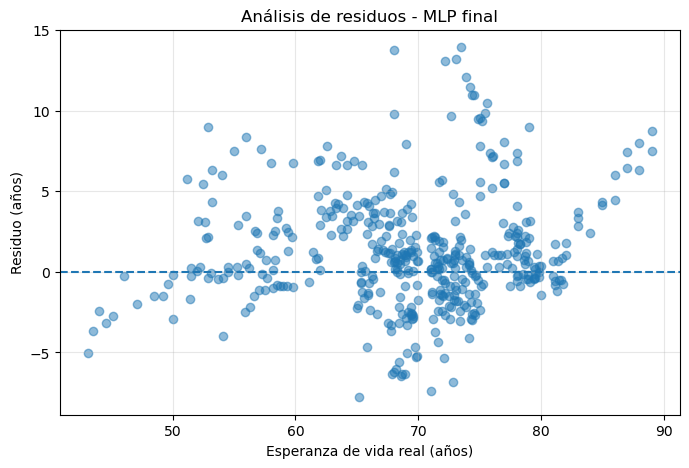

In [52]:
residuos = y_test.values - pred_test_final

plt.figure(figsize=(8, 5))

plt.scatter(y_test, residuos, alpha=0.5)

plt.axhline(0, linestyle="--")

plt.xlabel("Esperanza de vida real (años)")
plt.ylabel("Residuo (años)")
plt.title("Análisis de residuos - MLP final")

plt.grid(alpha=0.3)
plt.show()

**Análisis de residuos**

La mayoría de los residuos se concentran alrededor de cero, aunque existen algunos errores superiores a 10 años.

También observamos cierta tendencia a sobreestimar algunas esperanzas de vida bajas y a subestimar algunas elevadas.

Esto indica que el modelo presenta un ajuste razonable en general, pero tiene dificultades con determinados registros y valores extremos.

In [53]:
mae_original = mean_absolute_error(y_val, pred_val_loss_mae)

importancias = []

for columna in X_val.columns:

    X_mezclado = X_val.copy()

    X_mezclado[columna] = np.random.default_rng(42).permutation(
        X_mezclado[columna].values
    )

    pred = modelo_loss_mae.predict(
        X_mezclado.astype("float32"), verbose=0
    ).ravel()

    nuevo_mae = mean_absolute_error(y_val, pred)

    importancias.append([columna, nuevo_mae - mae_original])

tabla_importancias = pd.DataFrame(
    importancias,
    columns=["Variable", "Aumento MAE"]
)

display(
    tabla_importancias.sort_values(
        "Aumento MAE", ascending=False
    ).head(10).round(3)
)

,Variable,Aumento MAE
2,Adult Mortality,4.049
13,HIV/AIDS,1.614
9,under-five deaths,1.481
3,infant deaths,1.031
19,Schooling,0.901
1,Status,0.587
17,thinness 5-9 years,0.391
5,percentage expenditure,0.253
0,Year,0.204
18,Income composition of resources,0.161


**Importancia de variables**

Mediante Permutation Importance observamos que Adult Mortality es la variable más importante para nuestra red neuronal, ya que al alterar sus valores el MAE aumenta aproximadamente 4.05 años.

También destacan HIV/AIDS, la mortalidad infantil y Schooling.

Estos resultados muestran que el modelo depende especialmente de indicadores relacionados con la mortalidad y la salud para predecir la esperanza de vida.

In [54]:

robustez = pd.DataFrame({
    "Status": test_df["Status"].values,
    "Error": np.abs(y_test.values - pred_test_final)
})

resultado_robustez = robustez.groupby("Status")["Error"].agg(
    ["count", "mean"]
)

resultado_robustez.columns = ["Registros", "MAE"]

display(resultado_robustez.round(2))

,Registros,MAE
Status,,
Developed,112,2.19
Developing,336,2.84


**Análisis de robustez**

Al comparar los resultados según el tipo de país, se puede ver que la red obtiene un MAE de 2.19 años en países desarrollados y de 2.84 en países en desarrollo.

Esto indica que el modelo tiene diferencias de rendimiento entre ambos, siendo menos preciso en los países en desarrollo.

Todavía existen limitaciones en su capacidad de generalización.

### Demostración con un registro no visto

Para comprobar el funcionamiento del modelo, realizo una predicción utilizando un registro del conjunto Test.


In [65]:
ejemplo = X_test.iloc[[0]]

prediccion = modelo_loss_mae.predict(
    ejemplo.astype("float32"),
    verbose=0
)[0][0]

print("País:", test_df.iloc[0]["Country"])
print("Año:", test_df.iloc[0]["Year"])
print("Esperanza de vida real:", y_test.iloc[0])
print("Esperanza de vida predicha:", round(float(prediccion), 2))

País: Algeria
Año: 2015
Esperanza de vida real: 75.6
Esperanza de vida predicha: 75.28


In [56]:
from sklearn.model_selection import GroupKFold

X_cv = train_df.drop(columns=["Country", "Life expectancy"])
y_cv = train_df["Life expectancy"]

cv = GroupKFold(n_splits=3)
maes_cv = []

for i, (idx_train, idx_val) in enumerate(
    cv.split(X_cv, y_cv, groups=train_df["Country"]), 1
):

    X_tr = X_cv.iloc[idx_train].copy()
    X_v = X_cv.iloc[idx_val].copy()

    y_tr = y_cv.iloc[idx_train]
    y_v = y_cv.iloc[idx_val]

    columnas_num = X_tr.select_dtypes(include="number").columns

    imp = SimpleImputer(strategy="median")

    X_tr[columnas_num] = imp.fit_transform(X_tr[columnas_num])
    X_v[columnas_num] = imp.transform(X_v[columnas_num])

    categorias = {"Developing": 0, "Developed": 1}

    X_tr["Status"] = X_tr["Status"].map(categorias)
    X_v["Status"] = X_v["Status"].map(categorias)

    escalador = StandardScaler()

    X_tr[columnas_num] = escalador.fit_transform(X_tr[columnas_num])
    X_v[columnas_num] = escalador.transform(X_v[columnas_num])

    tf.keras.utils.set_random_seed(42)

    modelo_cv = tf.keras.Sequential([
        tf.keras.Input(shape=(20,)),
        tf.keras.layers.Dense(64, activation="tanh"),
        tf.keras.layers.Dense(1)
    ])

    modelo_cv.compile(optimizer="adam", loss="mae")

    modelo_cv.fit(
        X_tr.astype("float32"),
        y_tr.astype("float32"),
        epochs=300,
        batch_size=32,
        verbose=0
    )

    pred = modelo_cv.predict(
        X_v.astype("float32"), verbose=0
    ).ravel()

    mae = mean_absolute_error(y_v, pred)
    maes_cv.append(mae)

    print(f"Fold {i}: MAE = {mae:.3f}")

print("\nMAE medio:", round(np.mean(maes_cv), 3))
print("Desviación estándar:", round(np.std(maes_cv), 3))

Fold 1: MAE = 2.599
Fold 2: MAE = 2.526
Fold 3: MAE = 2.489

MAE medio: 2.538
Desviación estándar: 0.046


**Validación cruzada**

Realizamos una validación cruzada de 3 particiones utilizando GroupKFold para evitar que los registros de un mismo país aparezcan en entrenamiento y validación simultáneamente.

Obtuvimos un MAE medio de 2.54 años y una desviación estándar de 0.046.

Los resultados son similares entre las tres particiones, lo que indica que el modelo presenta un comportamiento relativamente estable al cambiar los países utilizados para entrenar y validar.

In [60]:

modelos_entrenados = {
    "Regresión lineal": (modelo_lineal, "Regresión lineal", "No aplica"),
    "Random Forest": (modelo_rf, "100 árboles", "No aplica"),
    "MLP 32 - 100 épocas": (modelo_mlp, "32 ReLU", "Adam (0.001)"),
    "MLP 32 - 300 épocas": (modelo_mlp_300, "32 ReLU", "Adam (0.001)"),
    "MLP 64 - ReLU": (modelo_mlp_64, "64 ReLU", "Adam (0.001)"),
    "MLP 64-32 - ReLU": (modelo_mlp_2capas, "64-32 ReLU", "Adam (0.001)"),
    "MLP 64 - tanh + MSE": (modelo_tanh, "64 tanh", "Adam (0.001)"),
    "MLP 64 - tanh + MAE": (modelo_loss_mae, "64 tanh", "Adam (0.001)"),
    "MLP + L2": (modelo_l2, "64 tanh + L2", "Adam (0.001)"),
    "MLP + Dropout": (modelo_dropout, "64 tanh + Dropout 0.2", "Adam (0.001)"),
    "MLP + BatchNorm": (modelo_bn, "64 tanh + BatchNorm", "Adam (0.001)"),
    "MLP + RMSprop": (modelo_rmsprop, "64 tanh", "RMSprop (0.001)"),
    "MLP + SGD": (modelo_sgd, "64 tanh", "SGD (0.001)"),
    "MLP 128 - KerasTuner": (modelo_optimizado, "128 tanh", "Adam (0.001)")
}

resultados_test = []

for nombre, (modelo, topologia, optimizador) in modelos_entrenados.items():

    if nombre in ["Regresión lineal", "Random Forest"]:
        pred = modelo.predict(X_test)
    else:
        pred = modelo.predict(
            X_test.astype("float32"),
            verbose=0
        ).ravel()

    metricas = evaluar_modelo(y_test, pred)

    resultados_test.append({
        "Modelo": nombre,
        "Topología / Capas": topologia,
        "Optimizador y LR": optimizador,
        "MAE Test": metricas["MAE"],
        "RMSE Test": metricas["RMSE"],
        "R² Test": metricas["R²"]
    })

tabla_final = tabla_resultados.merge(
    pd.DataFrame(resultados_test),
    on="Modelo"
)

columnas = [
    "Modelo",
    "Topología / Capas",
    "Optimizador y LR",
    "MAE Train", "MAE Val", "MAE Test",
    "RMSE Train", "RMSE Val", "RMSE Test",
    "R² Train", "R² Val", "R² Test"
]

display(
    tabla_final[columnas].sort_values("MAE Val").round(3)
)

,Modelo,Topología / Capas,Optimizador y LR,MAE Train,MAE Val,MAE Test,RMSE Train,RMSE Val,RMSE Test,R² Train,R² Val,R² Test
1,Random Forest,100 árboles,No aplica,0.394,1.908,2.304,0.676,2.772,2.912,0.995,0.921,0.883
7,MLP 64 - tanh + MAE,64 tanh,Adam (0.001),1.369,1.945,2.682,2.286,2.883,3.750,0.944,0.915,0.806
8,MLP + L2,64 tanh + L2,Adam (0.001),1.478,2.054,2.542,2.385,2.898,3.445,0.939,0.914,0.836
6,MLP 64 - tanh + MSE,64 tanh,Adam (0.001),1.465,2.101,2.701,2.094,2.924,3.590,0.953,0.912,0.822
11,MLP + RMSprop,64 tanh,RMSprop (0.001),1.372,2.171,2.634,2.284,3.105,3.591,0.944,0.901,0.822
13,MLP 128 - KerasTuner,128 tanh,Adam (0.001),1.245,2.245,2.540,2.157,3.163,3.423,0.950,0.897,0.838
12,MLP + SGD,64 tanh,SGD (0.001),1.774,2.259,2.656,2.682,3.144,3.807,0.923,0.898,0.800
10,MLP + BatchNorm,64 tanh + BatchNorm,Adam (0.001),1.703,2.338,2.620,2.443,3.223,3.367,0.936,0.893,0.843
4,MLP 64 - ReLU,64 ReLU,Adam (0.001),1.232,2.451,2.524,1.788,3.392,3.391,0.966,0.882,0.841
9,MLP + Dropout,64 tanh + Dropout 0.2,Adam (0.001),1.811,2.514,3.389,2.618,3.810,4.983,0.926,0.851,0.657


### Conclusiones de la comparación

Tras comparar los 14 modelos entrenados, observamos que Random Forest consigue los mejores resultados globales, con un MAE de 2.30 años y un R² de 0.883 en Test.

Entre las redes neuronales, seleccionamos la MLP de 64 neuronas con activación tanh, función de pérdida MAE y optimizador Adam, porque fue la que obtuvo el menor error de validación (1.95 años).

En Test, esta red alcanza un MAE de 2.68 años y un R² de 0.806. Aunque algunas alternativas obtienen mejores resultados en Test, mantenemos la selección realizada previamente para evitar utilizar este conjunto en la elección del modelo.

Los experimentos también muestran que aumentar el número de neuronas o añadir regularización no garantiza una mejora del rendimiento.

En conclusión, nuestra red neuronal consigue resultados razonables, aunque Random Forest demuestra una mayor precisión para este problema.